<a href="https://colab.research.google.com/github/TZBDragon/LinAlg344TZB/blob/main/notebooks/05_hero_figure.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Generating the big conclusion figure

In [6]:
import os
import subprocess
import sys
USER = "tzbdragon"
REPO = "LinAlg344TZB"
if os.path.exists(REPO):
  subprocess.run(['git', '-C', REPO, 'pull'], check=True)
else:
  subprocess.run(
  ['git', 'clone', f'https://github.com/{USER}/{REPO}.git', REPO],
  check=True)
sys.path.insert(0, f'{REPO}/src')
from compress import rank_k_approx, rel_error, predicted_error, compression_ratio, k_for_error
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from PIL import Image
P = np.array(Image.open(f"{REPO}/data/TZB_7471.JPG").convert('L')).astype(float)

IMports, I also bring in my image here just to be quicker with things

k = 5: 482x smaller, 20.6% error
k = 20: 120x smaller, 16.6% error
k = 50: 48x smaller, 14.6% error


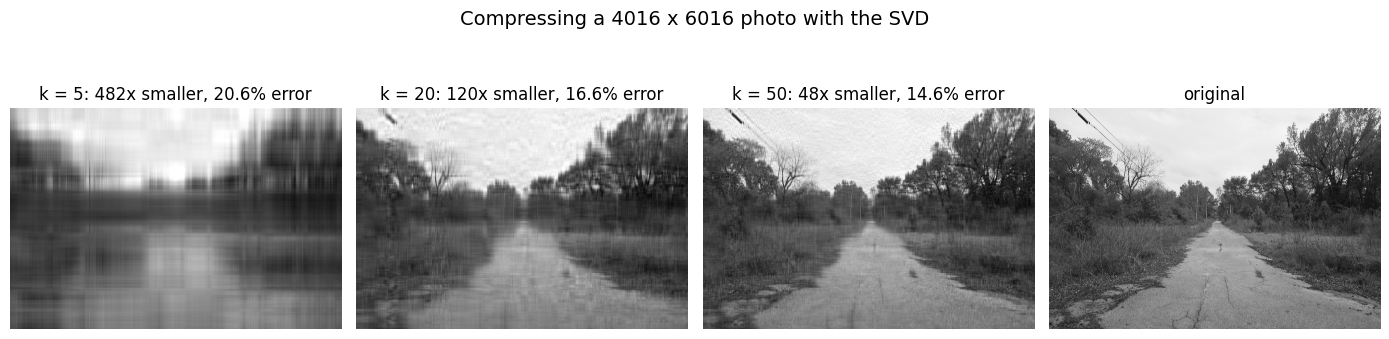

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
A = P
m, n = A.shape
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, k in zip(axes, [5, 20, 50]):
  Ak = np.clip(rank_k_approx(A, k), 0, 255)
  title = (f"k = {k}: {compression_ratio(m, n, k):.0f}x smaller, "
    f"{100 * rel_error(A, Ak):.1f}% error")
  print(title)
  ax.imshow(Ak, cmap="gray", vmin=0, vmax=255)
  ax.set_title(title)
  ax.axis("off")
axes[3].imshow(A, cmap="gray", vmin=0, vmax=255)
axes[3].set_title("original")
axes[3].axis("off")
plt.suptitle(f"Compressing a {m} x {n} photo with the SVD", fontsize=14)
plt.tight_layout()
plt.savefig("hero.png", dpi=150)
plt.show()

Compress the provided image to lower and lower K values and display the compression ratio as well as the error.

In [8]:
!pip freeze | grep -iE "^(numpy|matplotlib|scikit-image|pillow)=="

matplotlib==3.10.0
numpy==2.4.6
pillow==11.3.0
scikit-image==0.25.2


for generating requirements.txt

What we found: A nature landscape compress well and can be very recognizable even when it is 120x smaller, but the visual artifacting is much higher than what a 16.6% error would suggest. This indicates that relative error is only one part of understanding how an image compresses.